# Exploração Inicial

In [11]:
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Edite para a pasta onde estão seus dados:
DATA_DIR = Path(r"C:\Códigos\IC\PIBIC_DMR_IR\data")
MAX_EXAMPLES = 10

if not DATA_DIR.exists():
    print(f"Pasta não encontrada: {DATA_DIR}\nEdite DATA_DIR e execute novamente.")
else:
    files = [p for p in DATA_DIR.rglob("*") if p.is_file()]
    print("Total de arquivos:", len(files))
    display(pd.DataFrame(Counter(p.suffix.lower() or "[sem extensão]" for p in files).most_common(),
                         columns=["extensão", "quantidade"]))
    png_files = sorted(p for p in files if p.suffix.lower() == ".png")
    txt_files = sorted(p for p in files if p.suffix.lower() == ".txt")
    print(f"PNG: {len(png_files)} | TXT: {len(txt_files)}")
    print("\nExemplos PNG:")
    for p in png_files[:MAX_EXAMPLES]: print("-", p.relative_to(DATA_DIR))
    print("\nExemplos TXT:")
    for p in txt_files[:MAX_EXAMPLES]: print("-", p.relative_to(DATA_DIR))

Total de arquivos: 2653


,extensão,quantidade
0,.png,1522
1,.txt,1128
2,.csv,2
3,[sem extensão],1


PNG: 1522 | TXT: 1128

Exemplos PNG:
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN0-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN1-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN10-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN11-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN12-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN13-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN14-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN15-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN16-esq.png
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Segmentadas\PAC_65_DN17-esq.png

Exemplos TXT:
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES\1050\Matrizes\PAC_65_DN0.txt
- raw\DMR-IR\12 Novos Casos de Testes\DOENTES

## 1. Dimensões e modos dos PNGs


In [3]:
png_rows = []
for p in png_files:
    try:
        with Image.open(p) as im:
            png_rows.append({"arquivo": str(p.relative_to(DATA_DIR)), "largura": im.width,
                             "altura": im.height, "modo": im.mode, "formato": im.format,
                             "bandas": ", ".join(im.getbands())})
    except Exception as e:
        png_rows.append({"arquivo": str(p.relative_to(DATA_DIR)), "largura": None,
                         "altura": None, "modo": "ERRO", "formato": None, "bandas": str(e)})
png_df = pd.DataFrame(png_rows)
display(png_df.head(30))
if not png_df.empty:
    print("Dimensões mais frequentes:")
    display(png_df.groupby(["largura","altura"], dropna=False).size()
            .reset_index(name="quantidade").sort_values("quantidade", ascending=False))
    print("Modos:")
    display(png_df["modo"].value_counts().rename_axis("modo").reset_index(name="quantidade"))

,arquivo,largura,altura,modo,formato,bandas
0,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
1,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
2,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
3,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
4,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
5,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
6,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
7,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
8,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"
9,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,640,480,LA,PNG,"L, A"


Dimensões mais frequentes:


,largura,altura,quantidade
0,640,480,1522


Modos:


,modo,quantidade
0,RGBA,721
1,LA,701
2,L,100


### Visualização de exemplos PNG


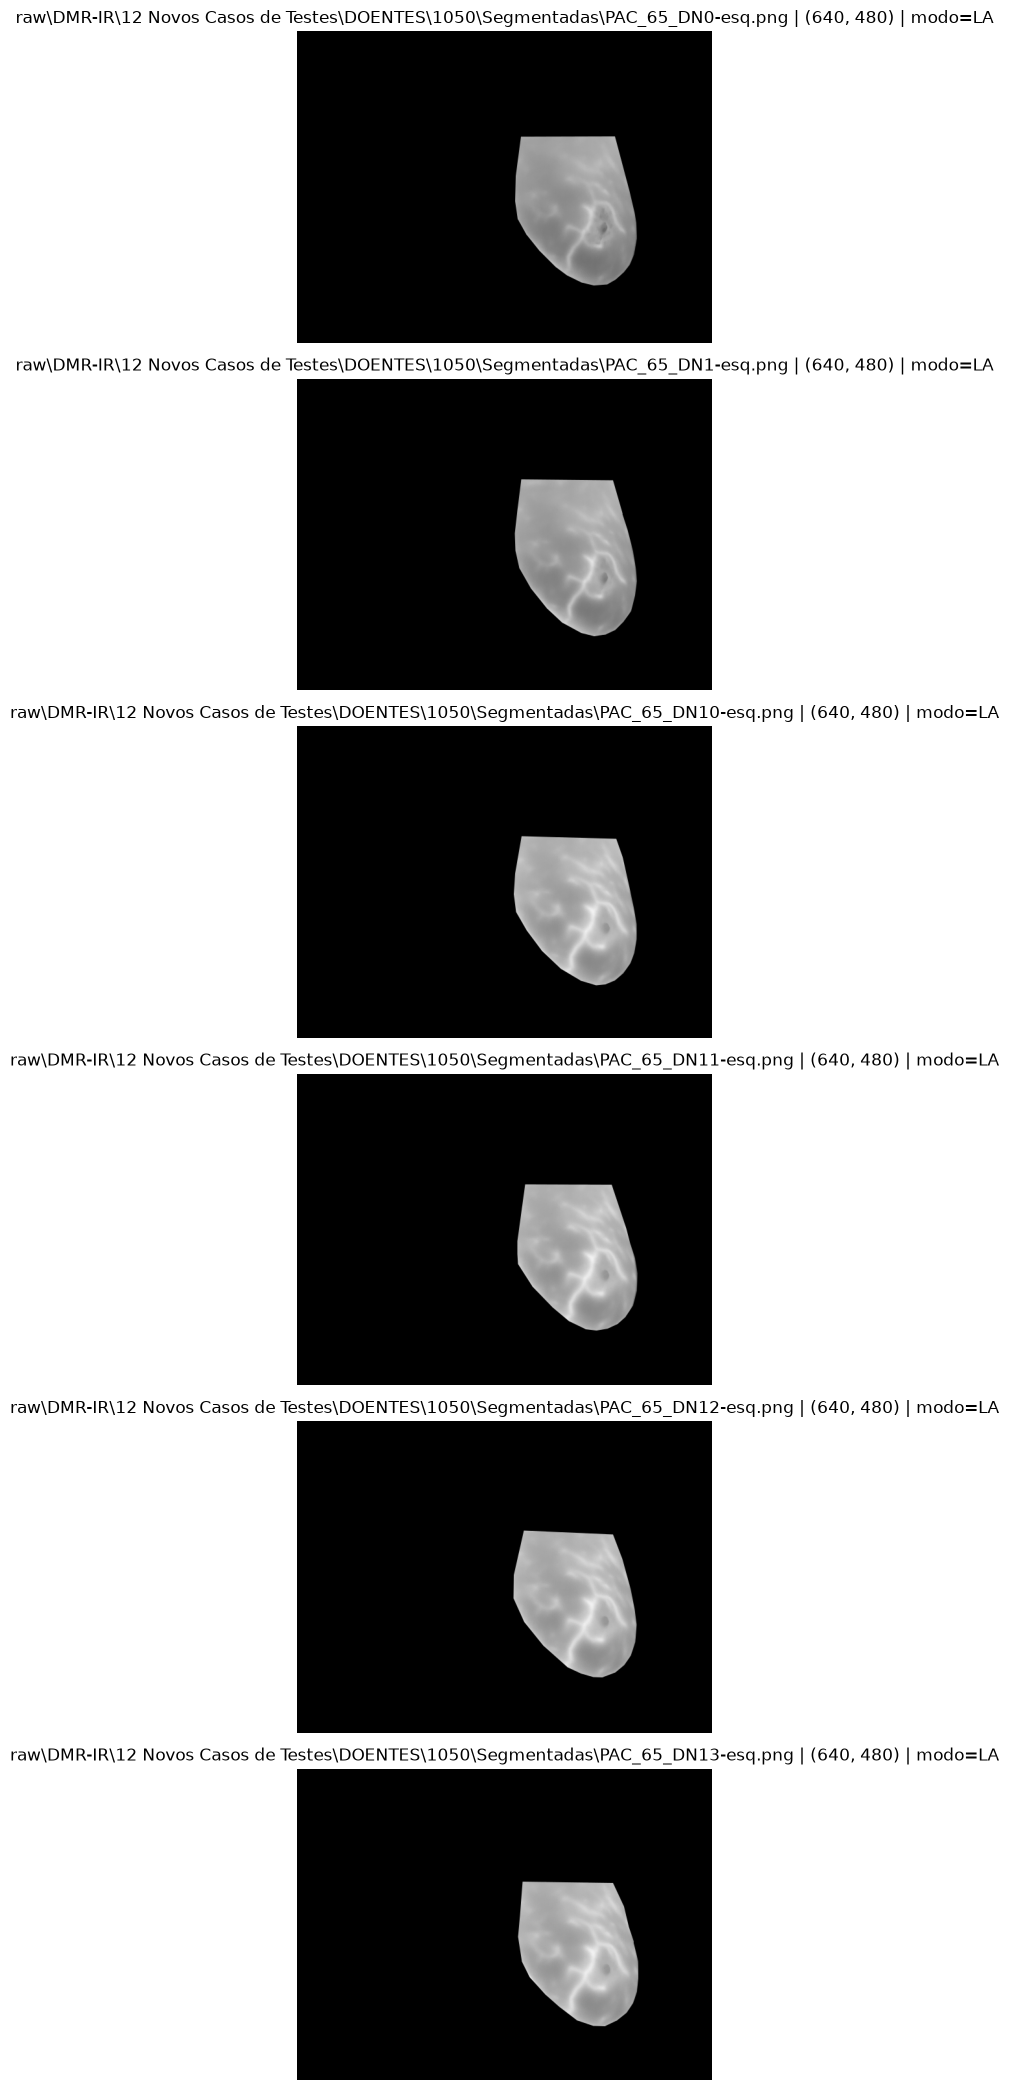

In [4]:
n = min(6, len(png_files))
if n:
    fig, axes = plt.subplots(n, 1, figsize=(7, 3.5*n), squeeze=False)
    for ax, p in zip(axes[:,0], png_files[:n]):
        try:
            with Image.open(p) as im:
                ax.imshow(im, cmap="gray" if im.mode in ("L","I","I;16","F") else None)
                ax.set_title(f"{p.relative_to(DATA_DIR)} | {im.size} | modo={im.mode}")
                ax.axis("off")
        except Exception as e:
            ax.text(0.05, 0.5, f"Erro ao abrir {p.name}: {e}")
            ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum PNG encontrado.")

## 2. Leitura numérica dos TXT


In [5]:
txt_rows = []
txt_arrays = {}
for p in txt_files:
    row = {"arquivo": str(p.relative_to(DATA_DIR)), "linhas_texto": None,
           "status": None, "shape": None, "ndim": None, "mínimo": None,
           "máximo": None, "média": None, "observação": None}
    try:
        lines = [line for line in p.read_text(encoding="utf-8", errors="replace").splitlines() if line.strip()]
        row["linhas_texto"] = len(lines)
        arr = np.asarray(np.loadtxt(p, dtype=float))
        row.update(status="OK", shape=str(arr.shape), ndim=arr.ndim,
                   mínimo=float(np.nanmin(arr)) if arr.size else None,
                   máximo=float(np.nanmax(arr)) if arr.size else None,
                   média=float(np.nanmean(arr)) if arr.size else None,
                   observação="Valores numéricos lidos; unidade não confirmada.")
        txt_arrays[p] = arr
    except Exception as e:
        row.update(status="FALHA", observação=f"{type(e).__name__}: {e}")
    txt_rows.append(row)
txt_df = pd.DataFrame(txt_rows)
display(txt_df.head(30))
if not txt_df.empty:
    display(txt_df["status"].value_counts().rename_axis("status").reset_index(name="quantidade"))

,arquivo,linhas_texto,status,shape,ndim,mínimo,máximo,média,observação
0,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.65,34.79,27.959967,Valores numéricos lidos; unidade não confirmada.
1,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.81,34.90,28.244199,Valores numéricos lidos; unidade não confirmada.
2,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.81,35.02,28.705961,Valores numéricos lidos; unidade não confirmada.
3,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.86,35.05,28.758107,Valores numéricos lidos; unidade não confirmada.
4,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.83,35.07,28.766162,Valores numéricos lidos; unidade não confirmada.
5,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.80,35.12,28.848798,Valores numéricos lidos; unidade não confirmada.
6,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.83,35.18,28.845657,Valores numéricos lidos; unidade não confirmada.
7,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.78,35.14,28.871412,Valores numéricos lidos; unidade não confirmada.
8,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.85,35.19,28.896890,Valores numéricos lidos; unidade não confirmada.
9,raw\DMR-IR\12 Novos Casos de Testes\DOENTES\10...,480,OK,"(480, 640)",2.0,21.80,35.22,28.867308,Valores numéricos lidos; unidade não confirmada.


,status,quantidade
0,OK,1126
1,FALHA,2


### Examinar TXT que falharam


In [6]:
failed = [p for p in txt_files if p not in txt_arrays]
for p in failed[:5]:
    print(f"\n--- {p.relative_to(DATA_DIR)} ---")
    try:
        for i, line in enumerate(p.read_text(encoding="utf-8", errors="replace").splitlines()[:8], 1):
            print(f"{i:>3}: {line[:250]}")
    except Exception as e:
        print("Erro:", e)
if not failed:
    print("Todos os TXT foram lidos numericamente com np.loadtxt().")


--- raw\DMR-IR\Desenvolvimento da Metodologia\DOENTES\259\Matrizes\PAC_35_ESTATICO.txt ---
  1: 31,78	31,69	32,03	31,99	31,99	32,16	32,14	32,17	32,48	32,43	32,41	32,62	32,61	32,72	32,42	32,83	32,51	32,71	32,78	32,82	32,73	32,84	32,71	32,85	32,89	32,91	32,89	32,65	32,91	32,68	32,79	32,68	32,8	32,7	32,71	32,74	32,68	32,64	32,63	32,65	32,55	32,63	
  2: 31,99	32,03	32,17	32,34	32,22	32,37	32,46	32,63	32,61	32,66	32,65	32,62	32,9	32,77	32,81	32,94	32,91	32,97	33,08	32,97	33,07	33,08	33,08	33,04	33,05	32,94	33,06	33,07	33,05	33,06	32,97	33,03	32,97	32,9	32,96	32,91	32,95	32,94	32,92	32,87	32,87	32,89	
  3: 31,99	32,01	32,17	32,18	32,2	32,21	32,48	32,48	32,64	32,66	32,67	32,77	32,92	32,88	32,95	33	32,92	32,96	32,95	33,1	33,02	33,1	33,06	33,09	33,1	33,08	33,05	33	33,08	33,06	33,07	32,98	33,03	32,89	32,85	32,93	32,94	32,94	32,87	32,92	32,86	32,85	32,89	32
  4: 32,09	32,03	32,2	32,21	32,32	32,34	32,49	32,5	32,7	32,63	32,65	32,76	32,87	32,8	32,9	32,92	32,9	33,07	33	33,08	32,99	33,06	33,09	33,08	

### Visualizar uma matriz TXT bidimensional


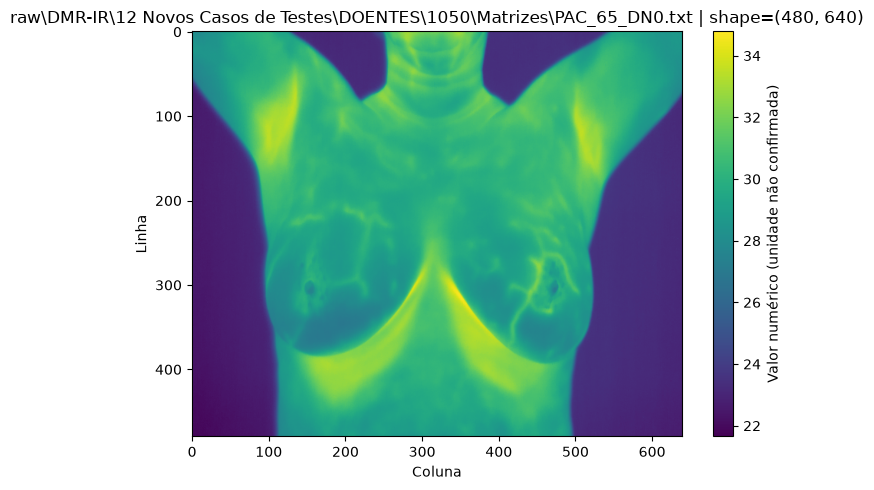

Shape: (480, 640) | mínimo: 21.65 | máximo: 34.79 | média: 27.959966829427085


In [7]:
matrices = [(p, a) for p, a in txt_arrays.items() if a.ndim == 2]
if matrices:
    p, arr = matrices[0]
    plt.figure(figsize=(7,5))
    plt.imshow(arr, aspect="auto")
    plt.colorbar(label="Valor numérico (unidade não confirmada)")
    plt.title(f"{p.relative_to(DATA_DIR)} | shape={arr.shape}")
    plt.xlabel("Coluna"); plt.ylabel("Linha")
    plt.tight_layout(); plt.show()
    print("Shape:", arr.shape, "| mínimo:", np.nanmin(arr),
          "| máximo:", np.nanmax(arr), "| média:", np.nanmean(arr))
else:
    print("Nenhuma matriz 2D lida com sucesso.")

## 3. Possíveis correspondências entre PNG e TXT
A comparação usa apenas o nome sem extensão. Um nome-base igual sugere um possível par, mas **não confirma** correspondência de imagem, paciente, ângulo ou classe.

In [8]:
png_by_stem = {p.stem: p for p in png_files}
txt_by_stem = {p.stem: p for p in txt_files}
common = sorted(set(png_by_stem) & set(txt_by_stem))
png_only = sorted(set(png_by_stem) - set(txt_by_stem))
txt_only = sorted(set(txt_by_stem) - set(png_by_stem))
print(f"Mesmo nome-base: {len(common)} | PNG sem par pelo nome: {len(png_only)} | TXT sem par pelo nome: {len(txt_only)}")
print("\nPossíveis pares (confirmar na documentação):")
for stem in common[:20]:
    print("PNG:", png_by_stem[stem].relative_to(DATA_DIR))
    print("TXT:", txt_by_stem[stem].relative_to(DATA_DIR), "\n")
print("Exemplos de PNG sem par:", [str(png_by_stem[s].relative_to(DATA_DIR)) for s in png_only[:10]])
print("Exemplos de TXT sem par:", [str(txt_by_stem[s].relative_to(DATA_DIR)) for s in txt_only[:10]])

Mesmo nome-base: 0 | PNG sem par pelo nome: 1522 | TXT sem par pelo nome: 1128

Possíveis pares (confirmar na documentação):
Exemplos de PNG sem par: ['raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN0-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN1-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN10-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN11-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN12-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN13-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN14-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN15-dir.png', 'raw\\DMR-IR\\Desenvolvimento da Metodologia\\DOENTES\\179\\Segmentadas\\PAC_00_DN16-dir.pn

## 4. Exportar relatórios de inspeção
Gera CSVs com metadados observados, úteis para documentar o inventário. Confira antes de versionar os relatórios no GitHub.

In [9]:
if DATA_DIR.exists():
    report_dir = DATA_DIR / "inspection_reports"
    report_dir.mkdir(parents=True, exist_ok=True)
    png_df.to_csv(report_dir / "png_inventory.csv", index=False, encoding="utf-8-sig")
    txt_df.to_csv(report_dir / "txt_inventory.csv", index=False, encoding="utf-8-sig")
    print("Relatórios salvos em:", report_dir)
else:
    print("Ajuste DATA_DIR antes de exportar.")

Relatórios salvos em: C:\Códigos\IC\PIBIC_DMR_IR\data\inspection_reports


In [14]:
from collections import defaultdict
import pandas as pd

# Agrupar arquivos por identificador do caso e nome-base do frame
txt_index = defaultdict(list)
png_index = defaultdict(list)

for p in txt_files:
    # Exemplo: .../DOENTES/1050/Matrizes/PAC_65_DN0.txt
    case_id = p.parent.parent.name
    key = (case_id, p.stem)
    txt_index[key].append(p)

for p in png_files:
    # Exemplo: .../DOENTES/1050/Segmentadas/PAC_65_DN0-esq.png
    case_id = p.parent.parent.name

    stem = p.stem
    if stem.endswith("-esq"):
        stem = stem[:-4]
    elif stem.endswith("-dir"):
        stem = stem[:-4]

    key = (case_id, stem)
    png_index[key].append(p)

# Construir relatório
keys = sorted(set(txt_index) | set(png_index))

rows = []
for case_id, stem in keys:
    txts = txt_index.get((case_id, stem), [])
    pngs = png_index.get((case_id, stem), [])

    rows.append({
        "caso": case_id,
        "identificador": stem,
        "quantidade_TXT": len(txts),
        "quantidade_PNG_segmentadas": len(pngs),
        "TXT": [str(p) for p in txts],
        "PNG": [str(p) for p in pngs],
        "possível_correspondência": bool(txts and pngs)
    })

matching_df = pd.DataFrame(rows)

display(matching_df.head(30))

print("Identificadores com TXT e PNG:",
      matching_df["possível_correspondência"].sum())

print("TXT sem PNG:",
      ((matching_df["quantidade_TXT"] > 0) &
       (matching_df["quantidade_PNG_segmentadas"] == 0)).sum())

print("PNG sem TXT:",
      ((matching_df["quantidade_PNG_segmentadas"] > 0) &
       (matching_df["quantidade_TXT"] == 0)).sum())

for _, row in matching_df[
    matching_df["quantidade_PNG_segmentadas"] == 2
].head(5).iterrows():

    print("\nCaso:", row["caso"])
    print("Identificador:", row["identificador"])

    print("\nTXT:")
    for p in row["TXT"]:
        print(p)

    print("\nPNG:")
    for p in row["PNG"]:
        print(p)

        pd.set_option("display.max_colwidth", None)

matching_df[
    matching_df["identificador"].isin([
        "PAC_38_DN0",
        "PAC_65_DN0"
    ])
][["caso", "identificador", "TXT", "PNG"]].to_string(index=False)

,caso,identificador,quantidade_TXT,quantidade_PNG_segmentadas,TXT,PNG,possível_correspondência
0,1000,PAC_38_DN0,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
1,1000,PAC_38_DN1,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
2,1000,PAC_38_DN10,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
3,1000,PAC_38_DN11,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
4,1000,PAC_38_DN12,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
5,1000,PAC_38_DN13,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
6,1000,PAC_38_DN14,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
7,1000,PAC_38_DN15,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
8,1000,PAC_38_DN16,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True
9,1000,PAC_38_DN17,1,2,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,[C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\De...,True


Identificadores com TXT e PNG: 1121
TXT sem PNG: 7
PNG sem TXT: 0

Caso: 1000
Identificador: PAC_38_DN0

TXT:
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS\1000\Matrizes\PAC_38_DN0.txt

PNG:
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS\1000\Segmentadas\PAC_38_DN0-dir.png
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS\1000\Segmentadas\PAC_38_DN0-esq.png

Caso: 1000
Identificador: PAC_38_DN1

TXT:
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS\1000\Matrizes\PAC_38_DN1.txt

PNG:
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS\1000\Segmentadas\PAC_38_DN1-dir.png
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS\1000\Segmentadas\PAC_38_DN1-esq.png

Caso: 1000
Identificador: PAC_38_DN10

TXT:
C:\Códigos\IC\PIBIC_DMR_IR\data\raw\DMR-IR\Desenvolvimento da Metodologia\SAUDAVÉIS

'caso identificador                                                                                                                TXT                                                                                                                                                                                                                                                PNG\n1000    PAC_38_DN0 [C:\\Códigos\\IC\\PIBIC_DMR_IR\\data\\raw\\DMR-IR\\Desenvolvimento da Metodologia\\SAUDAVÉIS\\1000\\Matrizes\\PAC_38_DN0.txt] [C:\\Códigos\\IC\\PIBIC_DMR_IR\\data\\raw\\DMR-IR\\Desenvolvimento da Metodologia\\SAUDAVÉIS\\1000\\Segmentadas\\PAC_38_DN0-dir.png, C:\\Códigos\\IC\\PIBIC_DMR_IR\\data\\raw\\DMR-IR\\Desenvolvimento da Metodologia\\SAUDAVÉIS\\1000\\Segmentadas\\PAC_38_DN0-esq.png]\n1050    PAC_65_DN0         [C:\\Códigos\\IC\\PIBIC_DMR_IR\\data\\raw\\DMR-IR\\12 Novos Casos de Testes\\DOENTES\\1050\\Matrizes\\PAC_65_DN0.txt]                                                                  

## 5. Registro de observações

### Observações confirmadas

- Quantidade de PNG: 1.522.
- Quantidade de TXT: 1.128.
- Dimensões PNG mais frequentes: 640 × 480 pixels.
- Modos de imagem encontrados: RGBA, LA e L.
- Dimensões das matrizes TXT: 480 × 640 (linhas × colunas).
- TXT lidos numericamente: 1.126.
- TXT com falha na leitura inicial: 2.
- Conforme Silva et al. (2020), os TXT descritos no artigo representam matrizes de temperatura, com valores em °C associados aos pixels.
- O mesmo artigo descreve a geração de imagens em escala de cinza a partir das matrizes térmicas e a segmentação manual das regiões de interesse (ROI).
- A estrutura local apresenta organização por conjuntos, classes e pastas de casos.